In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import mannwhitneyu, ttest_ind

MT, STABLE = 'LGG_MT', 'LGG_noMT'
COLOR = {MT: '#724C6D', STABLE: '#E69E84'}
TUMOR_COLOR, OLIG_COLOR, ENPP2_COLOR, LPAR1_COLOR, GRAY = '#DD8452', '#4C72B0', '#55A868', '#A76FB9', '#E6E6E6'

RISK = './Notebook_2_simulation_risk_score/source_data'
PAIRS = './Notebook_4_pairs_fdr/source_data'
LR_PAIRS = './Notebook_5_tumor_LR_pairs/source_data'
DEPTH = './Notebook_6_depth_equalized/source_data'
NO_CELLTYPE = './Notebook_7_no_celltype/source_data'
AUTOCRINE = './Notebook_8_autocrine/source_data'
NO_SPATIAL = './Notebook_9_no_spatial/source_data'

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'], 'font.size': 8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 150})

### helpers
- one value per patient, stable left and MT right
- p values: two-sided Mann-Whitney, 8 future MT v 7 future stable patients

In [2]:
def mw_p(d, column):
    return mannwhitneyu(d.loc[d.arm == MT, column].dropna(), d.loc[d.arm == STABLE, column].dropna()).pvalue


def box_gray_dots(ax, d, column, fliers=False):
    rng = np.random.default_rng(0)
    for i, arm in enumerate([STABLE, MT]):
        v = d.loc[d.arm == arm, column].dropna()
        ax.boxplot(v, positions=[i], widths=0.6, showfliers=fliers, patch_artist=True,
                   boxprops=dict(facecolor=COLOR[arm], lw=0.5), medianprops=dict(color='k', lw=0.5),
                   whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5), flierprops=dict(markersize=7, markeredgewidth=0.5))
        ax.scatter(i + rng.uniform(-0.1, 0.1, len(v)), v, s=9, c='k', alpha=0.4, lw=0, zorder=3)
    ax.set_xticks([0, 1], ['Future stable', 'Future MT'])


def box_arm_dots(ax, d, column):
    rng = np.random.default_rng(0)
    for i, arm in enumerate([STABLE, MT]):
        v = d.loc[d.arm == arm, column].dropna()
        ax.boxplot(v, positions=[i], widths=0.55, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=COLOR[arm], alpha=0.6, lw=0.5), medianprops=dict(color='k', lw=1.2),
                   whiskerprops=dict(lw=0.7), capprops=dict(lw=0.7))
        ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=10, c=COLOR[arm], edgecolor='k', lw=0.5, zorder=3)
    ax.set_xticks([0, 1], ['Stable', 'MT'])


def bracket(ax, y, text, height=0.02):
    ax.plot([0, 0, 1, 1], [y - height, y, y, y - height], color='k', lw=0.6, clip_on=False)
    ax.text(0.5, y, text, ha='center', va='bottom')


def welch_p(d, column):
    p = ttest_ind(d.loc[d.arm == MT, column], d.loc[d.arm == STABLE, column], equal_var=False).pvalue
    return f'{p:.1E}'.replace('E-0', 'E-')


def scatter_box(d, xlabel, ylabel, xlim=None, xticks=None, legend=False):
    d = d.dropna(subset=['box_frac'])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(4.2, 2.2), gridspec_kw=dict(width_ratios=[1.5, 1], wspace=0.5))
    for arm, name in [(STABLE, 'stable'), (MT, 'MT')]:
        e = d[d.arm == arm]
        ax1.scatter(e.src_frac, e.tgt_frac, s=22, c=COLOR[arm], edgecolor='w', lw=0.4, label=name)
    if legend:
        ax1.legend(frameon=False, loc='upper left', handletextpad=0.1, borderaxespad=0)
    if xlim:
        ax1.set_xlim(xlim)
    if xticks:
        ax1.set_xticks(xticks)
    ax1.set(xlabel=xlabel, ylabel=ylabel)
    box_gray_dots(ax2, d, 'box_frac')
    ax2.set_xticks([0, 1], ['stable', 'MT'])
    ax2.set_ylabel('Fraction co-loc co-exp pairs')
    top = d.box_frac.max()
    bracket(ax2, 1.08 * top, '***', height=0.02 * top)


def risk_map(ax, x, y, risk, size):
    points = ax.scatter(x, y, c=risk, cmap='RdBu_r', vmin=0, vmax=1, s=size, lw=0)
    ax.set_aspect('equal')
    ax.axis('off')
    return points


def scale_bar(ax, x, y, length, label):
    ax.plot([x, x + length], [y, y], color='k', lw=1.5, clip_on=False, solid_capstyle='butt')
    ax.text(x + length / 2, y, label, ha='center', va='top', style='italic', fontsize=6)

## Figure 4
- panel a is a schematic, and panels f, g are not part of this folder
- panels d, e: the analysis is in `./Notebook_3_high_low_risk_DE` and is not plotted here

### panel b: risk score over simulation steps
- mean risk score of each patient, from the gene-expression classifier (`./Notebook_2_simulation_risk_score/source_code/3_classifier.py`)
- middle: mean of each arm and 95% CI over patients; step 6 in red

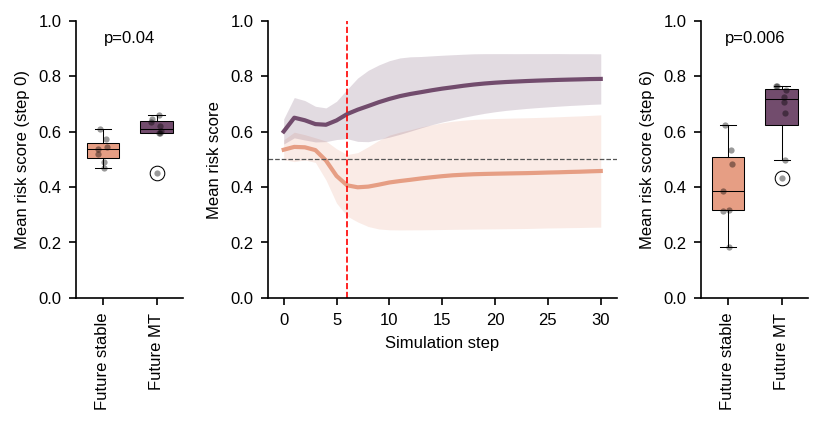

In [3]:
risk = pd.read_csv(f'{RISK}/risk_by_patient.csv', dtype={'patient_id': str})

fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.4), gridspec_kw=dict(width_ratios=[0.8, 2.6, 0.8], wspace=0.45))
for ax, step in [(axes[0], 0), (axes[2], 6)]:
    d = risk[risk.step == step]
    box_gray_dots(ax, d, 'mean_risk', fliers=True)
    ax.tick_params(axis='x', rotation=90)
    ax.set(ylim=(0, 1), ylabel=f'Mean risk score (step {step})')
    ax.text(0.5, 0.92, f'p={mw_p(d, "mean_risk"):.1g}', ha='center')

for arm in [STABLE, MT]:
    by_step = risk[risk.arm == arm].groupby('step').mean_risk
    mean, ci = by_step.mean(), 1.96 * by_step.std() / np.sqrt(by_step.size())
    axes[1].plot(mean.index, mean, color=COLOR[arm], lw=2)
    axes[1].fill_between(mean.index, mean - ci, mean + ci, color=COLOR[arm], alpha=0.2, lw=0)
axes[1].axhline(0.5, color='#555555', lw=0.6, ls='--')
axes[1].axvline(6, color='red', lw=0.8, ls='--')
axes[1].set(ylim=(0, 1), xticks=range(0, 31, 5), xlabel='Simulation step', ylabel='Mean risk score');

### panel c: per-cell risk score, steps 0-6
- sections 4970 (future stable, rotated by 90 degrees) and 2683 (future MT)

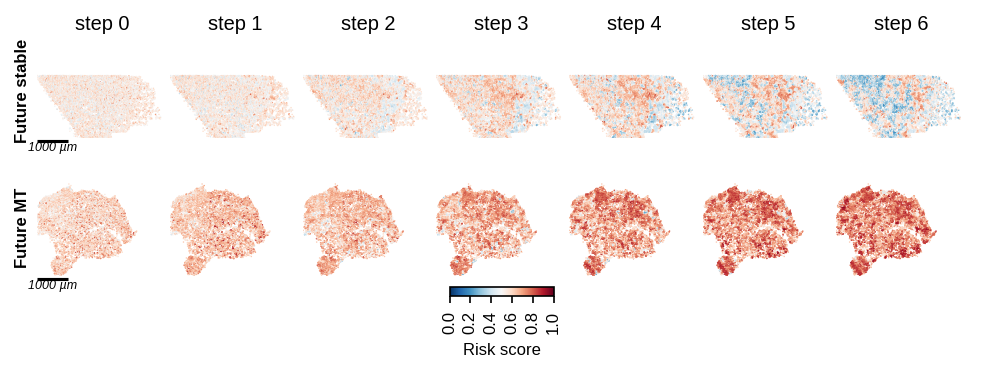

In [4]:
fig, axes = plt.subplots(2, 7, figsize=(8, 2.5), gridspec_kw=dict(hspace=0.05, wspace=0.02))
for row, section, name in zip(axes, ['4970', '2683'], ['Future stable', 'Future MT']):
    d = pd.read_csv(f'{RISK}/percell_risk_{section}.csv')
    x, y = (-d.y, d.x) if section == '4970' else (d.x, d.y)
    for step, ax in enumerate(row):
        points = risk_map(ax, x, y, d[f'risk_step{step}'], size=0.5)
        ax.set(xlim=(x.min(), x.min() + 4200), ylim=(y.min(), y.min() + 3100))
    scale_bar(row[0], x.min(), y.min() - 100, 1000, '1000 µm')
    row[0].text(-0.05, 0.5, name, transform=row[0].transAxes, rotation=90, ha='right', va='center', fontweight='bold')
for step, ax in enumerate(axes[0]):
    ax.set_title(f'step {step}')
colorbar = fig.colorbar(points, ax=axes, orientation='horizontal', fraction=0.03, pad=0.04, aspect=12, label='Risk score', ticks=np.arange(0, 1.01, 0.2))
colorbar.ax.tick_params(labelrotation=90);

## Figure 5
- panels c, f, g are not part of this folder

### panel a: representative sections
- sections 4970 (future stable) and 2683 (future MT), in the same orientation as the figure
- left: tumour and Olig. normal cells (top), and the cells in Olig. normal - tumour pairs within 50 µm (bottom)
- inset: ENPP2+ Olig. normal and LPAR1+ tumour cells (left), and the cells in cross-expressing pairs (right)

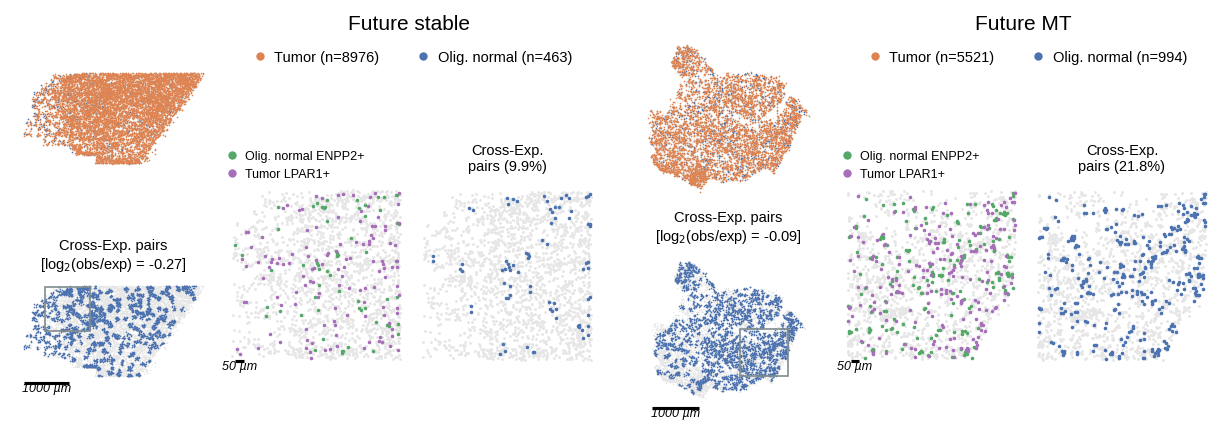

In [5]:
cells = pd.read_csv(f'{PAIRS}/fig5a_cells.csv', dtype={'section': str})
stats = pd.read_csv(f'{PAIRS}/fig5a_stats.csv', dtype={'section': str}).set_index('section')
stable, mt = cells[cells.section == '4970'], cells[cells.section == '2683']
views = [('Future stable', '4970', stable.assign(px=stable.y, py=stable.x), (500, 1500, 1000, 2000)),
         ('Future MT', '2683', mt.assign(px=mt.x, py=-mt.y), (2000, 3000, -2500, -1500))]

fig = plt.figure(figsize=(8.2, 3))
for k, (title, section, d, (x0, x1, y0, y1)) in enumerate(views):
    inset = d[d.px.between(x0, x1) & d.py.between(y0, y1)]
    s = stats.loc[section]
    left = 0.01 + k * 0.5
    a, b = fig.add_axes([left, 0.56, 0.16, 0.36]), fig.add_axes([left, 0.08, 0.16, 0.36])
    c, e = fig.add_axes([left + 0.17, 0.08, 0.15, 0.62]), fig.add_axes([left + 0.325, 0.08, 0.15, 0.62])

    a.scatter(d.px, d.py, s=0.4, c=GRAY, lw=0)
    a.scatter(d.px[d.celltype == 'Olig. normal'], d.py[d.celltype == 'Olig. normal'], s=0.6, c=OLIG_COLOR, lw=0)
    a.scatter(d.px[d.celltype == 'tumor'], d.py[d.celltype == 'tumor'], s=0.6, c=TUMOR_COLOR, lw=0)
    b.scatter(d.px, d.py, s=0.4, c=GRAY, lw=0)
    b.scatter(d.px[d.in_pair], d.py[d.in_pair], s=0.6, c=OLIG_COLOR, lw=0)
    b.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='#7F8C8D', lw=0.8))
    scale_bar(b, d.px.min(), d.py.min() - 150, 1000, '1000 µm')
    b.set_title(f'Cross-Exp. pairs\n[log$_2$(obs/exp) = {s.log2_obs_exp:.2f}]', fontsize=7, y=1.0)

    c.scatter(inset.px, inset.py, s=2, c=GRAY, lw=0)
    enpp2 = inset[(inset.celltype == 'Olig. normal') & inset.ENPP2_pos]
    lpar1 = inset[(inset.celltype == 'tumor') & inset.LPAR1_pos]
    c.scatter(enpp2.px, enpp2.py, s=3, c=ENPP2_COLOR, lw=0)
    c.scatter(lpar1.px, lpar1.py, s=3, c=LPAR1_COLOR, lw=0)
    scale_bar(c, x0 + 20, y0 - 15, 50, '50 µm')
    e.scatter(inset.px, inset.py, s=2, c=GRAY, lw=0)
    e.scatter(inset.px[inset.in_cross_pair], inset.py[inset.in_cross_pair], s=3, c=OLIG_COLOR, lw=0)

    c.legend(handles=[Line2D([], [], marker='o', ls='', ms=3, c=ENPP2_COLOR, label='Olig. normal ENPP2+'),
                      Line2D([], [], marker='o', ls='', ms=3, c=LPAR1_COLOR, label='Tumor LPAR1+')],
             frameon=False, fontsize=6, loc='lower left', bbox_to_anchor=(-0.05, 0.98), handletextpad=0, borderaxespad=0)
    e.set_title(f'Cross-Exp.\npairs ({100 * s.cross_fraction:.1f}%)', fontsize=7)
    fig.text(left + 0.32, 0.97, title, ha='center', va='top', fontsize=10)
    fig.legend(handles=[Line2D([], [], marker='o', ls='', ms=3, c=TUMOR_COLOR, label=f'Tumor (n={s.n_tumor:.0f})'),
                        Line2D([], [], marker='o', ls='', ms=3, c=OLIG_COLOR, label=f'Olig. normal (n={s.n_olig:.0f})')],
               ncol=2, frameon=False, fontsize=7, loc='upper center', bbox_to_anchor=(left + 0.32, 0.92), handletextpad=0)
    for ax in (a, b, c, e):
        ax.set_aspect('equal')
        ax.axis('off')

### panels b, d, e: cross-expressing cell pairs
- `pairs23.csv` holds the 23 pairs; pair 08 is panel b, pair 16 is panel d, pair 22 is panel e
- scatter: share of ligand+ senders and receptor+ receivers among the cells with a partner cell within 50 µm
- boxplot: share of the 50 µm cell pairs that co-express the two genes

In [6]:
pairs = pd.read_csv(f'{PAIRS}/pairs23_per_patient.csv', dtype={'pair_id': str, 'patient_id': str})
pd.read_csv(f'{PAIRS}/pairs23.csv', dtype={'pair_id': str})[['pair_id', 'source', 'gene_1', 'target', 'gene_2', 'p_value', 'mt_mean', 'stable_mean']]

,pair_id,source,gene_1,target,gene_2,p_value,mt_mean,stable_mean
0,01,Endothelial,ENPP2,tumor,LPAR1,0.000311,0.093686,0.015389
1,02,Microglia,ENPP2,Endothelial,LPAR1,0.000311,0.057295,0.009458
2,03,Microglia,ENPP2,Olig. normal,LPAR1,0.000311,0.181364,0.048339
3,04,Microglia,ENPP2,tumor,LPAR1,0.000311,0.074860,0.007704
4,05,Neuron GABA.,ENPP2,Microglia,LPAR1,0.000311,0.086139,0.028074
5,06,Neuron GABA.,ENPP2,tumor,LPAR1,0.000311,0.065056,0.011984
6,07,Olig. normal,ENPP2,Microglia,LPAR1,0.000311,0.361169,0.146687
7,08,Olig. normal,ENPP2,tumor,LPAR1,0.000311,0.302576,0.059186
8,09,Pericytes,ENPP2,tumor,LPAR1,0.000311,0.072308,0.010218
9,10,tumor,ENPP2,Microglia,LPAR1,0.000311,0.085845,0.014457


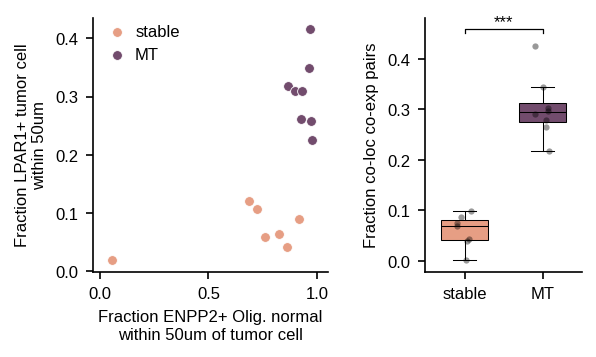

In [7]:
scatter_box(pairs[pairs.pair_id == '08'], 'Fraction ENPP2+ Olig. normal\nwithin 50um of tumor cell', 'Fraction LPAR1+ tumor cell\nwithin 50um', xlim=(-0.03, 1.05), xticks=[0, 0.5, 1], legend=True);

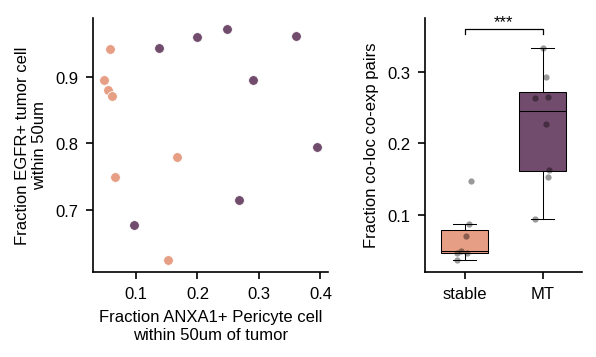

In [8]:
scatter_box(pairs[pairs.pair_id == '16'], 'Fraction ANXA1+ Pericyte cell\nwithin 50um of tumor', 'Fraction EGFR+ tumor cell\nwithin 50um');

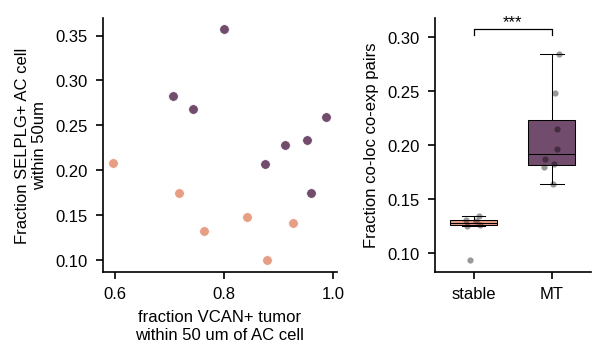

In [9]:
scatter_box(pairs[pairs.pair_id == '22'], 'fraction VCAN+ tumor\nwithin 50 um of AC cell', 'Fraction SELPLG+ AC cell\nwithin 50um');

## Figure S9
- per-cell risk score at simulation steps 0-6, three future MT and three future stable sections

In [10]:
def risk_rows(sections, title):
    fig, axes = plt.subplots(3, 7, figsize=(8, 3.1), gridspec_kw=dict(hspace=0.05, wspace=0.02))
    for row, section in zip(axes, sections):
        d = pd.read_csv(f'{RISK}/percell_risk_{section}.csv')
        for step, ax in enumerate(row):
            points = risk_map(ax, d.x, d.y, d[f'risk_step{step}'], size=0.5)
        scale_bar(row[0], d.x.min(), d.y.min() - 150, 1000, '1000 µm')
    for step, ax in enumerate(axes[0]):
        ax.set_title(f'step{step}', fontsize=7)
    fig.suptitle(title, fontweight='bold', fontsize=10, y=0.98)
    fig.colorbar(points, ax=axes, fraction=0.012, pad=0.01, label='Risk score', ticks=[0, 0.5, 1])

### panel a: future MT

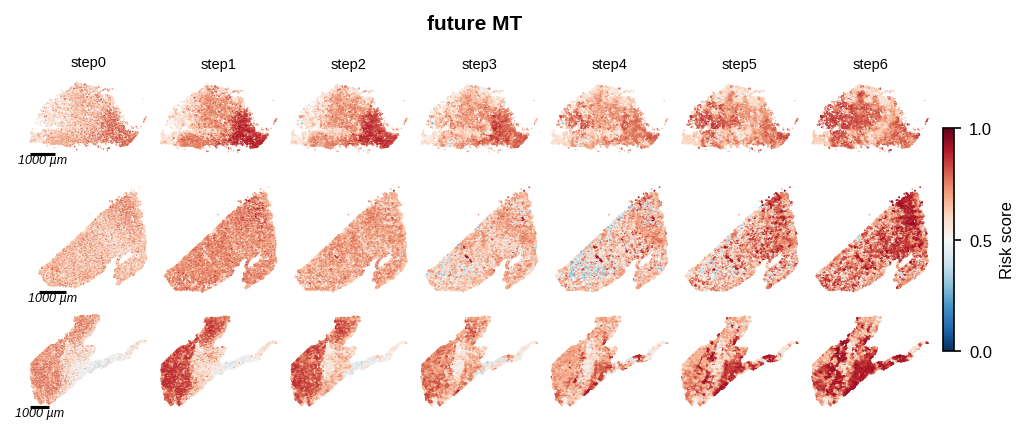

In [11]:
risk_rows(['2122', '3557', '2830'], 'future MT')

### panel b: future stable

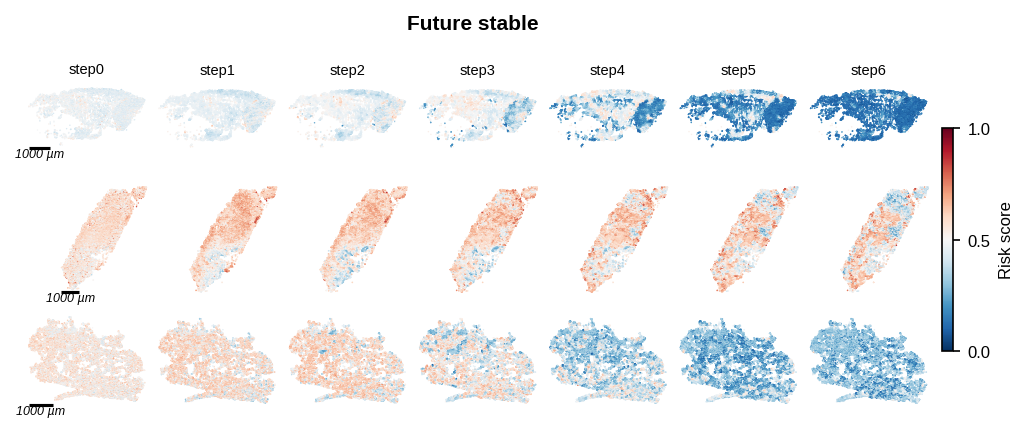

In [12]:
risk_rows(['5272_2', '4668', '4523'], 'Future stable')

## Figure S10
- panels b, g, h are not part of this folder

### panel a: ligand-receptor pairs from the high v low risk DE of the tumour cells
- 161 pairs with enough touching cells; BH is over all 227 tested pairs

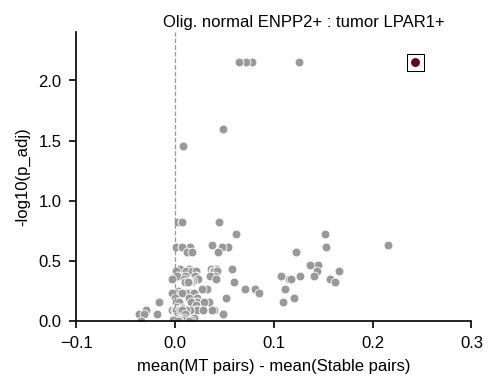

In [13]:
lr = pd.read_csv(f'{LR_PAIRS}/pairs_tested.csv')
lr['diff'], lr['log_p'] = lr.mt_mean - lr.stable_mean, -np.log10(lr.p_bh)
top = lr[(lr.source == 'Olig. normal') & (lr.gene_1 == 'ENPP2') & (lr.target == 'tumor') & (lr.gene_2 == 'LPAR1')]

fig, ax = plt.subplots(figsize=(3.4, 2.5))
ax.axvline(0, color='#999999', lw=0.6, ls='--')
ax.scatter(lr['diff'], lr.log_p, s=18, c='#999999', edgecolor='w', lw=0.4)
ax.scatter(top['diff'], top.log_p, s=18, c='#67001F', lw=0)
ax.scatter(top['diff'], top.log_p, s=70, marker='s', facecolor='none', edgecolor='k', lw=0.5)
ax.text(0.13, 2.42, 'Olig. normal ENPP2+ : tumor LPAR1+', ha='center', va='bottom')
ax.set(xlim=(-0.1, 0.3), ylim=(0, 2.4), xlabel='mean(MT pairs) - mean(Stable pairs)', ylabel='-log10(p_adj)');

### panel c: pair 08 before and after depth equalization
- every ROI brought to the same transcripts per cell (396), seed 1

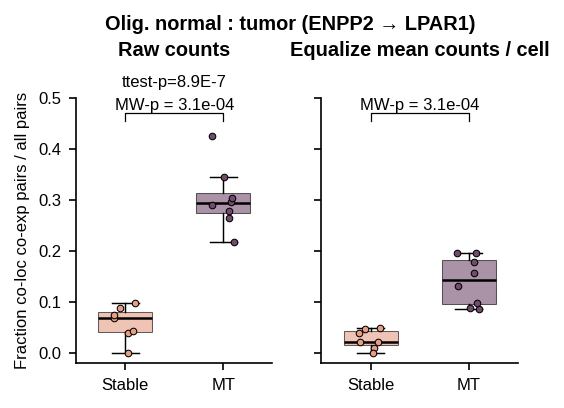

In [14]:
depth = pd.read_csv(f'{DEPTH}/pair08_raw_vs_equalized.csv', dtype={'patient_id': str})
raw, equalized = depth[depth.version == 'raw'], depth[depth.version == 'depth_equalized']

fig, axes = plt.subplots(1, 2, figsize=(3.8, 2.3), sharey=True, gridspec_kw=dict(wspace=0.25))
for ax, d, title in [(axes[0], raw, 'Raw counts'), (axes[1], equalized, 'Equalize mean counts / cell')]:
    box_arm_dots(ax, d, 'box_frac')
    bracket(ax, 0.47, f'MW-p = {mw_p(d, "box_frac"):.1e}', height=0.015)
    ax.set_title(title, fontweight='bold', pad=20)
axes[0].text(0.5, 0.515, f'ttest-p={welch_p(raw, "box_frac")}', ha='center', va='bottom')
axes[0].set_ylabel('Fraction co-loc co-exp pairs / all pairs')
axes[0].set_ylim(-0.02, 0.5)
fig.suptitle('Olig. normal : tumor (ENPP2 → LPAR1)', fontweight='bold', y=1.12);

### panel d: ENPP2 → LPAR1 without cell types
- every cell is a sender and a receiver

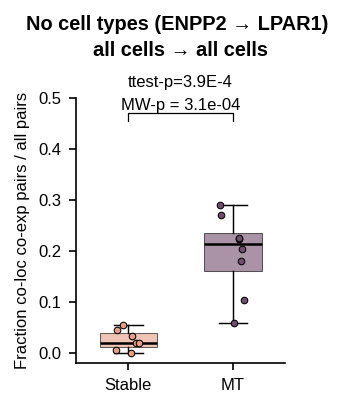

In [15]:
no_type = pd.read_csv(f'{NO_CELLTYPE}/enpp2_lpar1_no_celltype.csv', dtype={'patient_id': str})

fig, ax = plt.subplots(figsize=(1.8, 2.3))
box_arm_dots(ax, no_type, 'box_frac')
bracket(ax, 0.47, f'MW-p = {mw_p(no_type, "box_frac"):.1e}', height=0.015)
ax.set_ylim(-0.02, 0.5)
ax.set_ylabel('Fraction co-loc co-exp pairs / all pairs')
ax.text(0.5, 0.515, f'ttest-p={welch_p(no_type, "box_frac")}', ha='center', va='bottom')
ax.set_title('all cells → all cells', fontweight='bold', pad=20)
fig.suptitle('No cell types (ENPP2 → LPAR1)', fontweight='bold', y=1.12);

### panel e: autocrine only
- share of all cells of the type that are ENPP2+ LPAR1+ with no ENPP2+ or LPAR1+ cell of the type within 50 µm

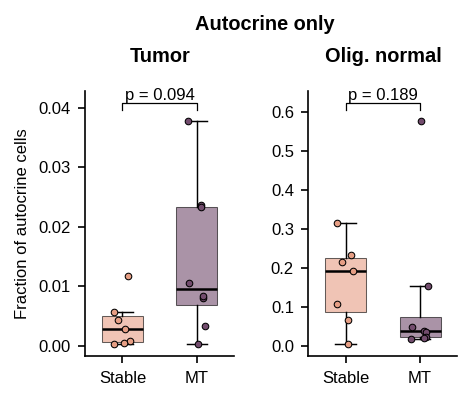

In [16]:
autocrine = pd.read_csv(f'{AUTOCRINE}/autocrine_only.csv', dtype={'patient_id': str})

fig, axes = plt.subplots(1, 2, figsize=(3.2, 2.3), gridspec_kw=dict(wspace=0.5))
for ax, celltype, title in [(axes[0], 'tumor', 'Tumor'), (axes[1], 'Olig. normal', 'Olig. normal')]:
    d = autocrine[autocrine.celltype == celltype]
    box_arm_dots(ax, d, 'frac_autocrine_only')
    top = d.frac_autocrine_only.max()
    bracket(ax, 1.08 * top, f'p = {mw_p(d, "frac_autocrine_only"):.3f}', height=0.03 * top)
    ax.set_title(title, fontweight='bold', pad=14)
axes[0].set_ylabel('Fraction of autocrine cells')
fig.suptitle('Autocrine only', fontweight='bold', y=1.1);

### panel f: top genes in tumour cells without spatial information
- S = stable; q = BH over all genes; q5% = BH over the genes detected in at least 5% of the tumour cells

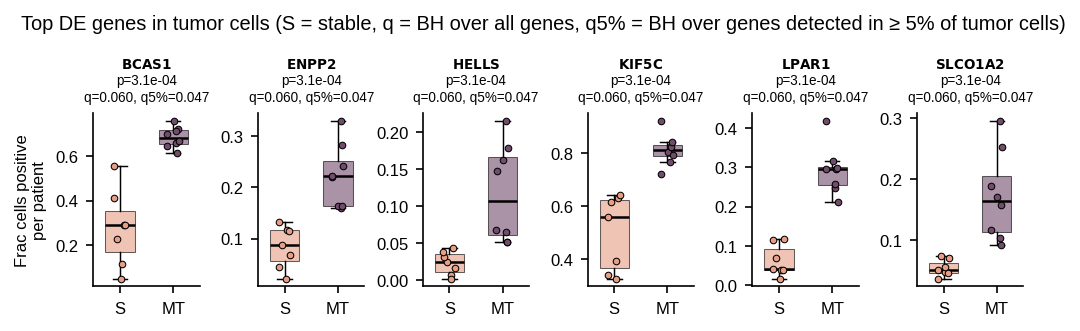

In [17]:
genes = pd.read_csv(f'{NO_SPATIAL}/tumor_genes.csv')
share = pd.read_csv(f'{NO_SPATIAL}/tumor_genes_per_patient.csv', dtype={'patient_id': str})
top_genes = genes[genes.q_5pct < 0.05]

fig, axes = plt.subplots(1, 6, figsize=(8, 1.5), gridspec_kw=dict(wspace=0.55))
for ax, g in zip(axes, top_genes.itertuples()):
    box_arm_dots(ax, share[share.gene == g.gene], 'share_positive')
    ax.set_xticks([0, 1], ['S', 'MT'])
    ax.set_title(f'$\\bf{{{g.gene}}}$\np={g.p:.1e}\nq={g.q:.3f}, q5%={g.q_5pct:.3f}', fontsize=6.5)
axes[0].set_ylabel('Frac cells positive\nper patient')
fig.suptitle('Top DE genes in tumor cells (S = stable, q = BH over all genes, q5% = BH over genes detected in ≥ 5% of tumor cells)', y=1.32);